# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st
from statsmodels.stats.proportion import proportions_ztest


In [2]:

df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
df.head ()



,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
df.info ()
print("\nValores nulos por columna:\n" , df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum ())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB

Valores nulos por columna:
 user_id           0
date              0
landing           0
region            0
dispositivo       0
traffic_source    0
user_type         0
converted         0
gasto             0
dtype: int64

Filas duplicadas: 0


✍️ **Comentario**: **Hallazgos de calidad de datos:**
- El dataset tiene 40,000 filas y 9 columnas, sin valores nulos ni filas duplicadas.
- Los 40,000 `user_id` son únicos y ningún usuario fue expuesto a ambas versiones, por lo que no hay contaminación entre grupos.
- La columna `date` es de tipo `object`; no afecta las pruebas estadísticas, pero para un análisis temporal debería convertirse a `datetime`.
- El experimento abarca del 2026-01-01 al 2026-01-28 (4 semanas).

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
print("Total de filas:", len(df))
print("Usuarios unicos:", df["user_id"].nunique())
print("user_id_duplicados:", df["user_id"].duplicated().sum())

# Verificar que ningún usuario aparezca en ambas versiones (contaminación del A/B)
usuarios_en_ambas = df.groupby("user_id")["landing"].nunique()
print("Usuarios expuestos a A y B:", (usuarios_en_ambas > 1).sum())


Total de filas: 40000
Usuarios unicos: 40000
user_id_duplicados: 0
Usuarios expuestos a A y B: 0


 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [9]:
# Resumen estadístico de usuarios que se convirtieron
df[df["converted"] == 1]["gasto"].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [10]:
# Validar reglas de negocio
print("Gastos negativos:", (df["gasto"] < 0).sum())
print("Convertidos con gasto = 0:", ((df["converted"] == 1) & (df["gasto"] == 0)).sum())
print("No convertidos con gasto > 0:", ((df["converted"] == 0) & (df["gasto"] > 0)).sum())
print("Valores únicos en converted:", df["converted"].unique())

Gastos negativos: 0
Convertidos con gasto = 0: 0
No convertidos con gasto > 0: 0
Valores únicos en converted: [1 0]


In [11]:
print("\nConteo de categorías:")
for col in ["landing", "region", "dispositivo", "traffic_source", "user_type", "converted"]:
    print(f"\n{col}:\n{df[col].value_counts()}")


Conteo de categorías:

landing:
B    20018
A    19982
Name: landing, dtype: int64

region:
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

dispositivo:
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

traffic_source:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

user_type:
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64

converted:
0    34294
1     5706
Name: converted, dtype: int64


✍️ **Comentario**: **Hallazgos de variables categóricas y gasto:**
- Todas las categorías son las esperadas y no hay errores de escritura.
- El experimento está balanceado: A = 19,982 usuarios y B = 20,018 usuarios.
- No hay gastos negativos, y el gasto es mayor a 0 solo cuando `converted = 1`. La regla de negocio se cumple.
- 5,706 usuarios convirtieron, con un gasto promedio de 65.37. Por eso el análisis de gasto se hace solo con usuarios convertidos.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [12]:
# Gasto por versión
gasto_A = df[(df["landing"] == "A") & (df["converted"] == 1)]["gasto"]
gasto_B = df[(df["landing"] == "B") & (df["converted"] == 1)]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [13]:
# Supuestos: comparar medias y varianzas
print(f"Gasto promedio A: {gasto_A.mean():.2f} | Varianza A: {gasto_A.var():.2f}")
print(f"Gasto promedio B: {gasto_B.mean():.2f} | Varianza B: {gasto_B.var():.2f}")

# Prueba de Levene: H0 = las varianzas son iguales
levene = st.levene(gasto_A, gasto_B)
print(f"Levene p-value: {levene.pvalue:.4f}")

Gasto promedio A: 61.09 | Varianza A: 833.79
Gasto promedio B: 68.75 | Varianza B: 1024.07
Levene p-value: 0.0000



**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios convertidos es igual en la página A y en la página B.
- **Hipótesis alternativa (H₁):** El gasto promedio de los usuarios convertidos es diferente entre la página A y la página B.

Nivel de significancia: α = 0.05. La prueba de Levene (p < 0.05) indicó varianzas diferentes, por lo que se usó `equal_var=False` (prueba de Welch).

In [14]:
# Aplicar prueba
alpha = 0.05
equal_var = levene.pvalue > alpha   # si Levene no rechaza H0, se asumen varianzas iguales

resultado_gasto = st.ttest_ind(gasto_A, gasto_B, equal_var=equal_var)

# Visualizar resultados
print(f"Estadístico : {resultado_gasto.statistic:.4f}")
print(f"Valor p: {resultado_gasto.pvalue:.4f}")



Estadístico : -9.4810
Valor p: 0.0000


In [15]:
if resultado_gasto.pvalue < alpha:
    print("Se rechaza H0: hay diferencia significativa en el gasto promedio entre A y B.")
else:
    print("No se rechaza H0: no hay evidencia de diferencia en el gasto promedio entre A y B.")

Se rechaza H0: hay diferencia significativa en el gasto promedio entre A y B.


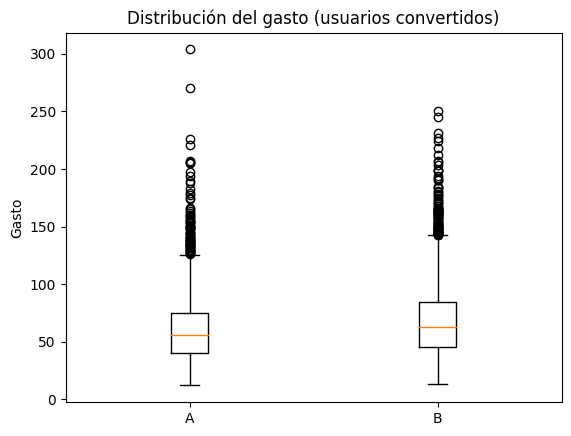

In [16]:
plt.boxplot([gasto_A, gasto_B], labels=["A", "B"])
plt.title("Distribución del gasto (usuarios convertidos)")
plt.ylabel("Gasto")
plt.show()

### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (p < 0.0001).

**Interpretación de negocio:**  
Los usuarios que compran en la página B gastan en promedio **68.75**, contra **61.09** en la página A: aproximadamente **12.5% más por compra**. La diferencia es estadísticamente significativa, por lo que la página B genera mayor valor económico por cliente.


---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba z para diferencia de proporciones

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión de la página A es igual a la de la página B.
- **Hipótesis alternativa (H₁):** La tasa de conversión de la página A es diferente a la de la página B.

Nivel de significancia: α = 0.05.

In [17]:
# Número de usuarios convertidos por página
convertidos = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
totales = df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", convertidos)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [18]:
tasa_conversion = convertidos / totales
print("Tasa de conversión por página:\n", (tasa_conversion * 100).round(2).astype(str) + " %")

Tasa de conversión por página:
 landing
A    12.57 %
B    15.96 %
Name: converted, dtype: object


In [19]:
# Aplicar prueba
z_stat, p_value_conv = proportions_ztest(count=convertidos.values, nobs=totales.values)

# Visualizar resultados
print(f"Estadístico : {z_stat:.4f}")
print(f"Valor p: {p_value_conv:.4f}")


Estadístico : -9.6774
Valor p: 0.0000


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (z = -9.68, p < 0.0001).

**Interpretación de negocio:**  
La página B convierte al **15.96%** contra **12.57%** de la página A: +3.4 puntos porcentuales, un aumento relativo de aproximadamente **27%**. Con un tráfico similar, B generó 682 compras más que A, así que es claramente más efectiva para convertir visitantes en clientes.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.


### Prueba Chi-cuadrada de independencia (χ²)

**Hipótesis:**
- **Hipótesis nula (H₀):** La conversión es independiente de la fuente de tráfico.
- **Hipótesis alternativa (H₁):** La conversión depende de la fuente de tráfico.

Nivel de significancia: α = 0.05. Supuesto verificado: todas las frecuencias esperadas son ≥ 5.

In [20]:
tabla_trafico = pd.crosstab(df["traffic_source"], df["converted"])
print(tabla_trafico)

print("\nTasa de conversión por fuente (%):")
print((df.groupby("traffic_source")["converted"].mean() * 100).round(2).sort_values(ascending=False))

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549

Tasa de conversión por fuente (%):
traffic_source
Email       14.99
Ads         14.74
Referral    13.88
Organic     13.79
Name: converted, dtype: float64


In [21]:
# Aplicar prueba
chi2_traf, p_traf, dof_traf, esperados_traf = st.chi2_contingency(tabla_trafico)

print(f"Estadístico χ²: {chi2_traf:.4f}")
print(f"Grados de libertad: {dof_traf}")
print(f"Valor p: {p_traf:.4f}")


Estadístico χ²: 8.6621
Grados de libertad: 3
Valor p: 0.0341


In [22]:
# Supuesto: todas las frecuencias esperadas deben ser >= 5
print("Frecuencias esperadas:\n", pd.DataFrame(esperados_traf, index=tabla_trafico.index, columns=tabla_trafico.columns).round(1))
print("¿Todas >= 5?:", (esperados_traf >= 5).all())

print("Se rechaza H0" if p_traf < alpha else "No se rechaza H0")

Frecuencias esperadas:
 converted             0       1
traffic_source                 
Ads             10232.5  1702.5
Email            5249.6   873.4
Organic         15421.2  2565.8
Referral         3390.8   564.2
¿Todas >= 5?: True
Se rechaza H0


### 📝 Conclusión e interpretación


**Decisión:**  
Se rechaza la hipótesis nula (χ² = 8.66, gl = 3, p = 0.034).

**Interpretación de negocio:**  
Existe una asociación significativa, aunque débil, entre la fuente de tráfico y la conversión. **Email (14.99%)** y **Ads (14.74%)** tienen las mejores tasas; **Organic (13.79%)** y **Referral (13.88%)** las más bajas. Sin embargo, en volumen absoluto Organic aporta más conversiones (2,480) por ser el canal con más tráfico. La diferencia entre canales es de apenas ~1.2 puntos, por lo que es relevante para optimizar presupuesto, pero no es un efecto grande.


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi-cuadrada de independencia (χ²)

**Hipótesis:**
- **Hipótesis nula (H₀):** La conversión es independiente del tipo de usuario.
- **Hipótesis alternativa (H₁):** La conversión depende del tipo de usuario.

Nivel de significancia: α = 0.05. Supuesto verificado: todas las frecuencias esperadas son ≥ 5.

In [23]:
tabla_usuario = pd.crosstab(df["user_type"], df["converted"])
print(tabla_usuario)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [24]:
print("Tasa de conversión por tipo de usuario (%):")
print((df.groupby("user_type")["converted"].mean() * 100).round(2))

Tasa de conversión por tipo de usuario (%):
user_type
Nuevo         14.36
Recurrente    14.09
Name: converted, dtype: float64


In [25]:
# Aplicar prueba
chi2_user, p_user, dof_user, esperados_user = st.chi2_contingency(tabla_usuario)

print(f"Estadístico χ²: {chi2_user:.4f}")
print(f"Grados de libertad: {dof_user}")
print(f"Valor p: {p_user:.4f}")
print("¿Frecuencias esperadas >= 5?:", (esperados_user >= 5).all())
print("Se rechaza H0" if p_user < alpha else "No se rechaza H0")


Estadístico χ²: 0.5135
Grados de libertad: 1
Valor p: 0.4736
¿Frecuencias esperadas >= 5?: True
No se rechaza H0


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula (χ² = 0.51, gl = 1, p = 0.474).

**Interpretación de negocio:**  
Los usuarios nuevos (14.36%) y recurrentes (14.09%) convierten prácticamente igual. No hay evidencia de que el tipo de usuario influya en la conversión, por lo que no se justifica crear experiencias diferenciadas por este criterio.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

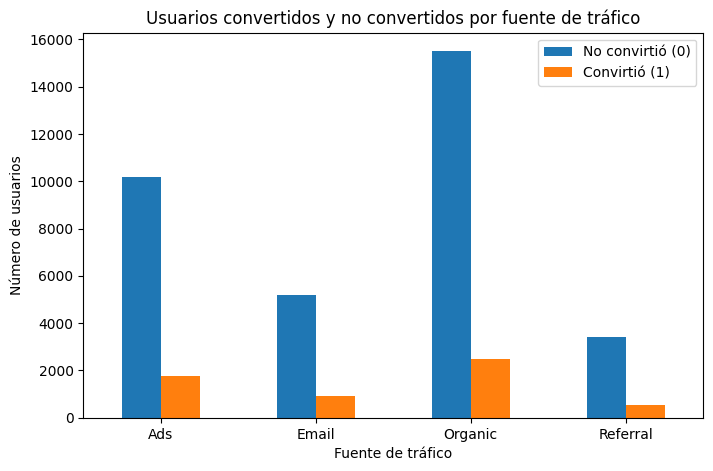

In [26]:
tabla_trafico.plot(kind="bar", figsize=(8, 5))
plt.title("Usuarios convertidos y no convertidos por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Número de usuarios")
plt.legend(["No convirtió (0)", "Convirtió (1)"])
plt.xticks(rotation=0)
plt.show()

In [27]:
print(tabla_trafico)

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549


✍️ **Comentario**:La gráfica muestra el volumen absoluto de usuarios que convirtieron y no convirtieron por canal. Organic es el canal con mayor tráfico y también con más conversiones (2,480), seguido de Ads (1,759). Email y Referral aportan menos volumen.

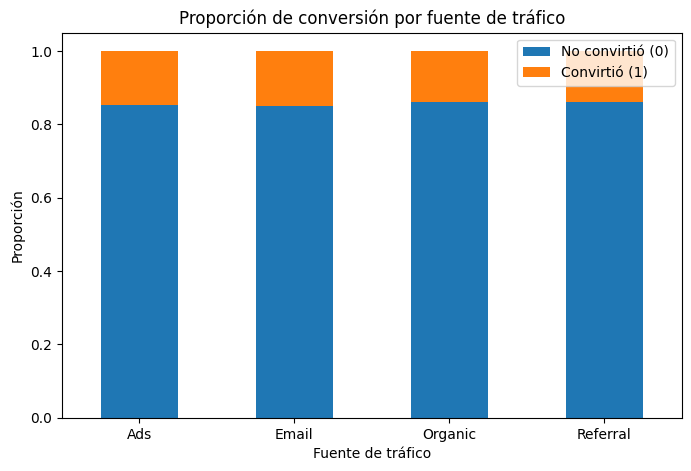

In [28]:
prop_trafico = pd.crosstab(df["traffic_source"], df["converted"], normalize="index")
prop_trafico.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Proporción de conversión por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Proporción")
plt.legend(["No convirtió (0)", "Convirtió (1)"])
plt.xticks(rotation=0)
plt.show()

In [29]:
(prop_trafico * 100).round(2)

converted,0,1
traffic_source,,
Ads,85.26,14.74
Email,85.01,14.99
Organic,86.21,13.79
Referral,86.12,13.88


✍️ **Comentario**: Al comparar proporciones, Email (14.99%) y Ads (14.74%) son los canales más efectivos, mientras que Organic (13.79%) y Referral (13.88%) convierten menos. Esto respalda el resultado de la prueba χ²: las diferencias existen, aunque son pequeñas.

### Relación entre el tipo de usuario y la conversión

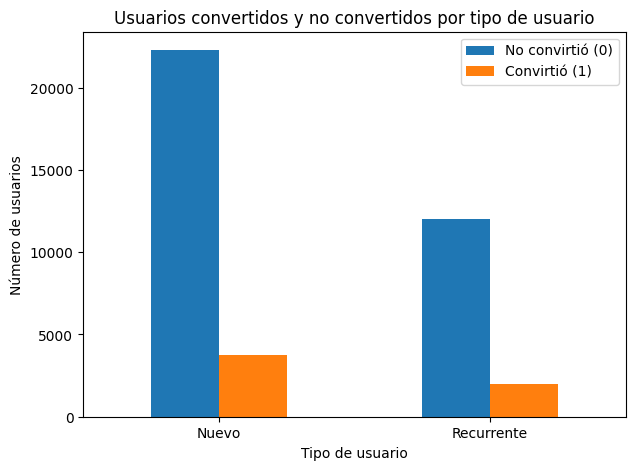

In [30]:
tabla_usuario.plot(kind="bar", figsize=(7, 5))
plt.title("Usuarios convertidos y no convertidos por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Número de usuarios")
plt.legend(["No convirtió (0)", "Convirtió (1)"])
plt.xticks(rotation=0)
plt.show()

In [31]:
print(tabla_usuario)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


✍️ **Comentario**:Los usuarios nuevos representan aproximadamente el 65% del tráfico y generan más conversiones en volumen (3,738 contra 1,968 de los recurrentes), simplemente porque son más.

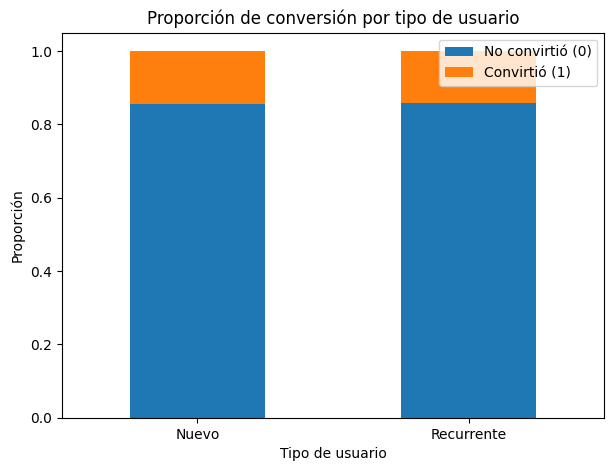

In [32]:
prop_usuario = pd.crosstab(df["user_type"], df["converted"], normalize="index")
prop_usuario.plot(kind="bar", stacked=True, figsize=(7, 5))
plt.title("Proporción de conversión por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Proporción")
plt.legend(["No convirtió (0)", "Convirtió (1)"])
plt.xticks(rotation=0)
plt.show()

In [33]:
(prop_usuario * 100).round(2)

converted,0,1
user_type,,
Nuevo,85.64,14.36
Recurrente,85.91,14.09


✍️ **Comentario**: En proporción, ambos grupos convierten casi igual (14.36% contra 14.09%); las barras son prácticamente idénticas. Esto confirma visualmente el resultado de la prueba χ²: el tipo de usuario no influye en la conversión.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- Página B: 68.75 contra página A: 61.09 (+12.5%).
- La diferencia es estadísticamente significativa (prueba de Welch, p < 0.0001).
- **Interpretación:** Los clientes de la página B gastan más por compra, por lo que B genera mayor valor económico.

<br>

**Tasa de conversión:** 
- Página B: 15.96% contra página A: 12.57% (+3.4 pp, aprox. +27% relativo).
- La diferencia es estadísticamente significativa (prueba z, p < 0.0001).
- **Interpretación:** B convierte más visitantes en clientes **y** esos clientes gastan más; gana en ambas métricas.

---

#### 📊 **Segmentación por fuente de tráfico**
- Email (14.99%) y Ads (14.74%) convierten mejor; Organic (13.79%) y Referral (13.88%) peor. La asociación es significativa (χ², p = 0.034), pero débil.
- **Interpretación:** Email y Ads son los canales más eficientes; Organic aporta el mayor volumen de conversiones por su tráfico.
 
 ---

#### 📊 **Segmentación por tipo de usuario**
- Nuevos 14.36% contra recurrentes 14.09%; sin diferencia significativa (χ², p = 0.474).
- **Interpretación:** No es necesario segmentar la experiencia por tipo de usuario.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 
- **Implementar la página B** para todo el tráfico: mejora tanto la conversión como el gasto por cliente.
- **Priorizar la inversión en Email y Ads**, que tienen la mejor tasa de conversión, sin descuidar Organic por su volumen.
- No invertir en experiencias diferenciadas para usuarios nuevos y recurrentes.

**Limitaciones:** el experimento duró solo 4 semanas (posible efecto novedad), y no se analizó si la ventaja de B se mantiene dentro de cada canal o región. Se recomienda monitorear las métricas después de la implementación.